In [6]:

import geopandas as gpd
import os
import re
import requests
import boto3
from rasterio.session import AWSSession
import numpy as np
import rasterio
import xarray as xr
import rioxarray
import matplotlib.pyplot as plt
import leafmap.maplibregl as leafmap

In [7]:
# 1. Ruta a tu archivo vectorial
aoi_path = "C:/Users/CAMILO/Desktop/Vectorial/Monserrate.shp"  # Cambia esto por tu archivo (.geojson, .shp, .gpkg)

# 2. Cargar el archivo vectorial usando GeoPandas  
gdf_aoi = gpd.read_file(aoi_path)

# 3. Garantizar que el CRS esté en WGS84 (EPSG:4326) para la API OData de CDSE
if gdf_aoi.crs != "EPSG:4326":
    gdf_aoi = gdf_aoi.to_crs(epsg=4326)

# 4. Extraer la geometría unificada y el Bounding Box (bbox)
# Si el archivo tiene múltiples polígonos, .union_all() los combina en uno solo
aoi_geometry = gdf_aoi.geometry.union_all()

# Obtener las coordenadas extremas [minx, miny, maxx, maxy]
minx, miny, maxx, maxy = aoi_geometry.bounds

print(" Sistema de Referencia Espacial (CRS):", gdf_aoi.crs)
print(" Extensión Geográfica (Bounding Box):", [minx, miny, maxx, maxy])
print(" Geometría WKT (Well-Known Text):", aoi_geometry.wkt[:100], "...")

 Sistema de Referencia Espacial (CRS): EPSG:4326
 Extensión Geográfica (Bounding Box): [-76.00515626999999, 2.441915601000062, -75.96800748199996, 2.5040494410000633]
 Geometría WKT (Well-Known Text): POLYGON ((-75.97458799699996 2.5022224710000387, -75.97445620199994 2.5021874660000663, -75.97432574 ...


In [8]:
os.environ["AWS_ACCESS_KEY_ID"] ="MMGLFL1X5TDP7637YWN8"
os.environ["AWS_SECRET_ACCESS_KEY"] = "Q1s94tsudm2Zh6OwZJw4xaQYt4nmqVYoBKPnEXFV"
os.environ["AWS_S3_ENDPOINT"] = "eodata.dataspace.copernicus.eu"
os.environ["AWS_VIRTUAL_HOSTING"] = "FALSE"
os.environ["GDAL_HTTP_UNSAFESSL"] = "YES"
os.environ["AWS_HTTPS"] = "YES"
os.environ["GDAL_HTTP_TCP_KEEPALIVE"] = "YES"

In [9]:
# Define a  function to inspect directories and raster datasets in Copernicus S3
def list_s3_resources(prefix_path=""):
    """
    Lists sub-directories and raster files (.tif, .tiff, .jp2) 
    within the Copernicus 'eodata' S3 bucket for a given prefix path.
    """
    s3_client = boto3.client(
        "s3",
        aws_access_key_id=os.environ["AWS_ACCESS_KEY_ID"],
        aws_secret_access_key=os.environ["AWS_SECRET_ACCESS_KEY"],
        endpoint_url=f"https://{os.environ['AWS_S3_ENDPOINT']}"
    )
    
    response = s3_client.list_objects_v2(
        Bucket="eodata",
        Prefix=prefix_path,
        Delimiter="/"
    )
    
    print(f"--- Contents in s3://eodata/{prefix_path} ---")
    # Print available subfolders and satellite collections
    folders = response.get("CommonPrefixes", [])
    for folder in folders:
        print(" 📁", folder.get("Prefix"))
        
    # Print raster data files if situated at the terminal folder level
    files = response.get("Contents", [])
    for file in files:
        key = file.get("Key")
        if key.endswith((".tif", ".tiff", ".jp2")):
            print(" 📄 /vsis3/eodata/" + key)

# List all primary satellite collections available at root level
list_s3_resources("")

--- Contents in s3://eodata/ ---
 📁 C3S/
 📁 CAMS/
 📁 CEMS/
 📁 CLMS/
 📁 CLMS_archive/
 📁 Envisat-ASAR/
 📁 Envisat/
 📁 Global-Mosaics/
 📁 Jason-3/
 📁 Landsat-5/
 📁 Landsat-7/
 📁 SMOS/
 📁 SRTM/
 📁 Sentinel-1-RTC/
 📁 Sentinel-1/
 📁 Sentinel-2/
 📁 Sentinel-3/
 📁 Sentinel-5P/
 📁 Sentinel-6/
 📁 auxdata/
 📁 geoAI-embeddings/
 📁 geoAI-training/


In [10]:
# Coordenadas geográficas del área de estudio (Bounding Box en EPSG:4326)
MIN_LON = -76.00515627
MIN_LAT = 2.441915601
MAX_LON = -75.96800748
MAX_LAT = 2.504049441

print(f"✅ Coordenadas definidas:")
print(f"   Lon: [{MIN_LON}, {MAX_LON}]")
print(f"   Lat: [{MIN_LAT}, {MAX_LAT}]")

✅ Coordenadas definidas:
   Lon: [-76.00515627, -75.96800748]
   Lat: [2.441915601, 2.504049441]


In [11]:
import re
import requests

# Coordenadas centrales derivadas de tu Bounding Box [-76.00515, 2.44191, -75.96800, 2.50404]
LATITUDE = 2.47298
LONGITUDE = -75.98658

def search_Monserrate_odata(lat, lon, start_date, end_date):
    """Queries the Copernicus OData endpoint for Sentinel-2 Level-2A products
    intersecting a spatial bounding box around the target location.
    Returns a structured list containing metadata for each matching satellite scene.
    """
    url = "https://catalogue.dataspace.copernicus.eu/odata/v1/Products"

    # Bounding box buffer (~10 km x 10 km)
    min_lon, max_lon = lon - 0.05, lon + 0.05
    min_lat, max_lat = lat - 0.05, lat + 0.05
    
    # Well-Known Text (WKT) POLYGON string sin espacios entre POLYGON y ((
    poly = f"POLYGON(({min_lon} {min_lat}, {max_lon} {min_lat}, {max_lon} {max_lat}, {min_lon} {max_lat}, {min_lon} {min_lat}))"

    # OData Query String corregida para la API OData v1 de CDSE
    filter_query = (
        f"Collection/Name eq 'SENTINEL-2' and "
        f"Attributes/OData.CSC.StringAttribute/any(att:att/Name eq 'productType' and att/Value eq 'S2MSI2A') and "
        f"OData.CSC.Intersects(area=geography'SRID=4326;{poly}') and "
        f"ContentDate/Start ge {start_date}T00:00:00.000Z and "
        f"ContentDate/Start le {end_date}T23:59:59.999Z"
    )
    
    params = {
        "$filter": filter_query,
        "$orderby": "ContentDate/Start desc",
        "$top": 50,
    }

    response = requests.get(url, params=params)
    response.raise_for_status()
    data = response.json()
    
    items = data.get("value", [])
    results = []
    
    print(f" Found {len(items)} matching Level-2A satellite scenes for range [{start_date} - {end_date}].\n" + "=" * 70)

    for idx, item in enumerate(items):
        s3_path = item.get("S3Path", "")
        date = item.get("ContentDate", {}).get("Start", "").split("T")[0]

        match = re.search(r"_(T\d{2}[A-Z]{3})_", s3_path)
        tile_id = match.group(1) if match else "N/A"

        results.append(
            {"index": idx, "date": date, "tile": tile_id, "s3_path": s3_path}
        )

        print(f"[{idx}] 📅 Date: {date} | 🧩 Detected tile: {tile_id}")
        print(f"    📦 S3 path: {s3_path}\n")

    return results

# ==========================================
# ESCENARIO 1: Marzo 2023
# ==========================================
print("🔴 EJECUTANDO BUSQUEDA - ESCENARIO 1 (Marzo 2023)")
escenario_1 = search_Monserrate_odata(
    LATITUDE, LONGITUDE, "2023-03-01", "2023-03-31"
)

# ==========================================
# ESCENARIO 2: Marzo 2024
# ==========================================
print("\n🔵 EJECUTANDO BUSQUEDA - ESCENARIO 2 (Marzo 2024)")
escenario_2 = search_Monserrate_odata(
    LATITUDE, LONGITUDE, "2024-03-01", "2024-03-31"
)

🔴 EJECUTANDO BUSQUEDA - ESCENARIO 1 (Marzo 2023)
 Found 6 matching Level-2A satellite scenes for range [2023-03-01 - 2023-03-31].
[0] 📅 Date: 2023-03-29 | 🧩 Detected tile: T18NUH
    📦 S3 path: /eodata/Sentinel-2/MSI/L2A_N0500/2023/03/29/S2B_MSIL2A_20230329T152639_N0510_R025_T18NUH_20240824T030224.SAFE

[1] 📅 Date: 2023-03-24 | 🧩 Detected tile: T18NUH
    📦 S3 path: /eodata/Sentinel-2/MSI/L2A_N0500/2023/03/24/S2A_MSIL2A_20230324T152641_N0510_R025_T18NUH_20240824T123203.SAFE

[2] 📅 Date: 2023-03-19 | 🧩 Detected tile: T18NUH
    📦 S3 path: /eodata/Sentinel-2/MSI/L2A_N0500/2023/03/19/S2B_MSIL2A_20230319T152639_N0510_R025_T18NUH_20240825T073251.SAFE

[3] 📅 Date: 2023-03-14 | 🧩 Detected tile: T18NUH
    📦 S3 path: /eodata/Sentinel-2/MSI/L2A_N0500/2023/03/14/S2A_MSIL2A_20230314T152641_N0510_R025_T18NUH_20240821T042223.SAFE

[4] 📅 Date: 2023-03-09 | 🧩 Detected tile: T18NUH
    📦 S3 path: /eodata/Sentinel-2/MSI/L2A_N0500/2023/03/09/S2B_MSIL2A_20230309T152649_N0510_R025_T18NUH_20240823T123510.S

In [12]:
import os
import boto3
import rasterio
import numpy as np
import geopandas as gpd
from rasterio.session import AWSSession
from rasterio.mask import mask
from shapely.wkt import loads
import matplotlib.pyplot as plt

# 1. Rutas S3 de tus 2 escenas seleccionadas (Reemplaza con tus rutas exactas)
S3_PATH_ESCENARIO_1 = "eodata/Sentinel-2/MSI/L2A/2023/03/15/S2B_MSIL2A_20230315T...SAFE"
S3_PATH_ESCENARIO_2 = "eodata/Sentinel-2/MSI/L2A/2024/03/15/S2A_MSIL2A_20240315T...SAFE"

# 2. Configurar cliente Boto3 y AWSSession para Rasterio Directo
session = boto3.Session(
    aws_access_key_id=os.environ["AWS_ACCESS_KEY_ID"],
    aws_secret_access_key=os.environ["AWS_SECRET_ACCESS_KEY"]
)
endpoint_url = f"https://{os.environ['AWS_S3_ENDPOINT']}"

# 3. Geometría de tu SHP en EPSG:4326
wkt_geometry = "POLYGON ((-75.97458799699996 2.5022224710000387, -75.97445620199994 2.5021874660000663, -75.97432574 2.502, -76.00515627 2.44191560, -75.96800748 2.44191560, -75.97458799699996 2.5022224710000387))"
geom_shape = loads(wkt_geometry)
gdf = gpd.GeoDataFrame(index=[0], crs="EPSG:4326", geometry=[geom_shape])

In [13]:
def process_ndvi_from_s3(s3_safe_path, gdf_aoi):
    """Accede a las bandas B04 y B08 en S3, recorta con la geometría dada y calcula NDVI."""
    
    # Construir ruta a la subcarpeta GRANULE / R10m
    # Nota: Las imágenes de 10m (B04 y B08) están en GRANULE/.../IMG_DATA/R10m/
    s3_base = f"s3://{s3_safe_path.strip('/')}/GRANULE"
    
    # Usar boto3 para localizar la carpeta exacta del gránulo
    s3_client = session.client("s3", endpoint_url=endpoint_url)
    bucket = "eodata"
    prefix = s3_safe_path.replace("eodata/", "").strip("/") + "/GRANULE/"
    
    resp = s3_client.list_objects_v2(Bucket=bucket, Prefix=prefix, Delimiter="/")
    granule_folder = resp.get("CommonPrefixes", [{}])[0].get("Prefix", "")
    
    # Rutas relativas a las bandas B04 (Red) y B08 (NIR)
    # Se busca el patrón _B04_10m.jp2 y _B08_10m.jp2
    r10m_prefix = granule_folder + "IMG_DATA/R10m/"
    resp_bands = s3_client.list_objects_v2(Bucket=bucket, Prefix=r10m_prefix)
    
    b04_key, b08_key = None, None
    for obj in resp_bands.get("Contents", []):
        key = obj["Key"]
        if key.endswith("B04_10m.jp2"):
            b04_key = key
        elif key.endswith("B08_10m.jp2"):
            b08_key = key
            
    aws_env = rasterio.env.Env(
        AWSSession(session, endpoint_url=endpoint_url),
        GDAL_DISABLE_READDIR_BEFORE_SIDECAR=True,
        AWS_S3_ENDPOINT=os.environ['AWS_S3_ENDPOINT']
    )
    
    with aws_env:
        # Abrir B04 y B08
        with rasterio.open(f"s3://{bucket}/{b04_key}") as src_red:
            # Reproyectar GeoDataFrame al CRS UTM de la imagen Sentinel-2
            gdf_utm = gdf_aoi.to_crs(src_red.crs)
            shapes = [gdf_utm.geometry.iloc[0]]
            
            # Recortar B04
            red_crop, _ = mask(src_red, shapes, crop=True)
            red = red_crop[0].astype(float)
            
        with rasterio.open(f"s3://{bucket}/{b08_key}") as src_nir:
            # Recortar B08
            nir_crop, _ = mask(src_nir, shapes, crop=True)
            nir = nir_crop[0].astype(float)
            
    # Calcular NDVI (evitando división por cero)
    denominator = nir + red
    ndvi = np.where(denominator == 0, np.nan, (nir - red) / denominator)
    ndvi = np.where((red == 0) & (nir == 0), np.nan, ndvi)
    
    return ndvi

⚡ Procesando Escenario 1 desde: /eodata/Sentinel-2/MSI/L2A_N0500/2023/03/29/S2B_MSIL2A_20230329T152639_N0510_R025_T18NUH_20240824T030224.SAFE
⚡ Procesando Escenario 2 desde: /eodata/Sentinel-2/MSI/L2A/2024/03/28/S2A_MSIL2A_20240328T152651_N0510_R025_T18NUH_20240328T220315.SAFE


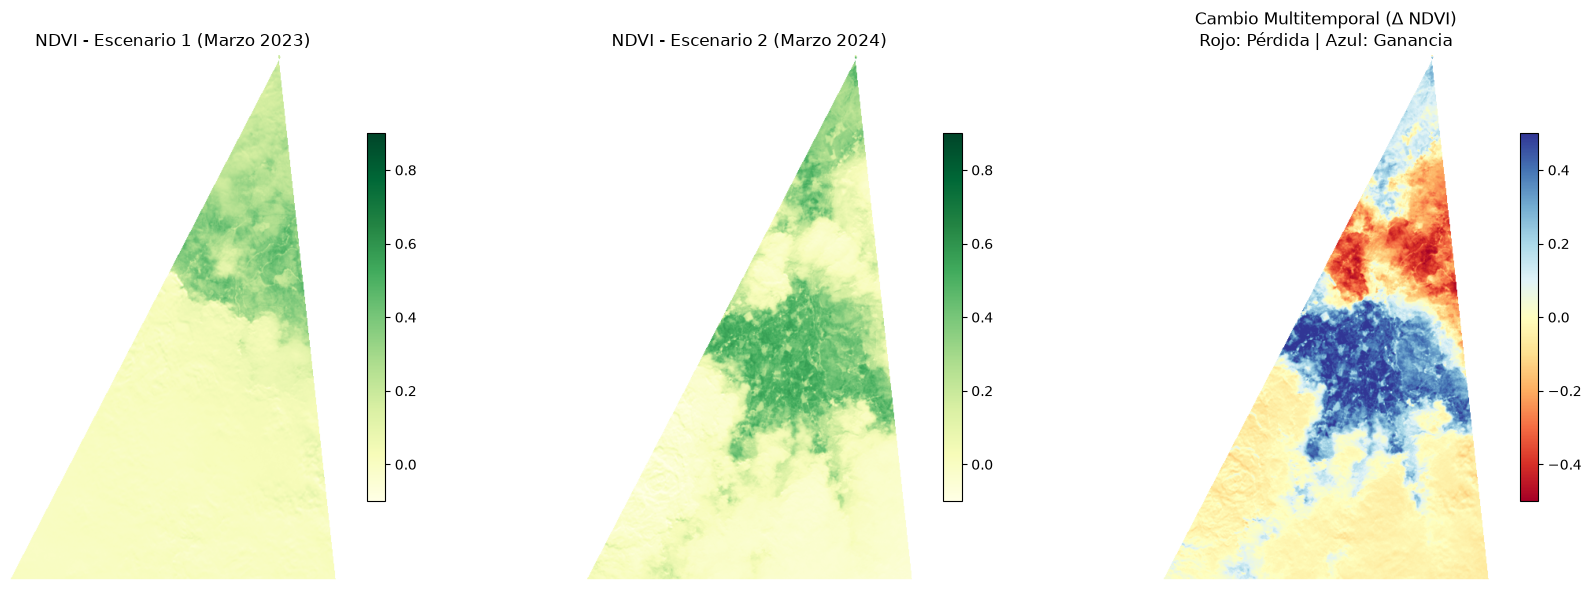

In [15]:
import os
import re
import boto3
import rasterio
import numpy as np
import geopandas as gpd
from rasterio.session import AWSSession
from rasterio.mask import mask
from shapely.wkt import loads
import matplotlib.pyplot as plt

# ==============================================================================
# 1. CONFIGURACIÓN DE CREDENCIALES Y AOI
# ==============================================================================
CDSE_S3_ENDPOINT = "eodata.dataspace.copernicus.eu"

ACCESS_KEY = os.environ.get("AWS_ACCESS_KEY_ID")
SECRET_KEY = os.environ.get("AWS_SECRET_ACCESS_KEY")

if not ACCESS_KEY or not SECRET_KEY:
    raise ValueError("❌ Las variables AWS_ACCESS_KEY_ID o AWS_SECRET_ACCESS_KEY no están configuradas.")

boto3_session = boto3.Session(
    aws_access_key_id=ACCESS_KEY,
    aws_secret_access_key=SECRET_KEY,
)

s3_client = boto3_session.client(
    "s3",
    endpoint_url=f"https://{CDSE_S3_ENDPOINT}",
)

# Polígono AOI (Colombia / EPSG:4326)
wkt_geometry = "POLYGON ((-75.97458799699996 2.5022224710000387, -75.97445620199994 2.5021874660000663, -75.97432574 2.502, -76.00515627 2.44191560, -75.96800748 2.44191560, -75.97458799699996 2.5022224710000387))"
geom_shape = loads(wkt_geometry)
gdf = gpd.GeoDataFrame(index=[0], crs="EPSG:4326", geometry=[geom_shape])

# ==============================================================================
# 2. FUNCIONES OPTIMIZADAS
# ==============================================================================
def find_bands_in_safe(s3_safe_prefix):
    """Obtiene rápidamente las llaves S3 para B04 y B08 directamente dentro de la carpeta .SAFE"""
    clean_prefix = s3_safe_prefix.replace("eodata/", "").strip("/") + "/"
    paginator = s3_client.get_paginator("list_objects_v2")
    
    b04_key, b08_key = None, None
    for page in paginator.paginate(Bucket="eodata", Prefix=clean_prefix):
        for obj in page.get("Contents", []):
            key = obj["Key"]
            if key.endswith("B04_10m.jp2"):
                b04_key = key
            elif key.endswith("B08_10m.jp2"):
                b08_key = key
            if b04_key and b08_key:
                return b04_key, b08_key
    return b04_key, b08_key

def process_ndvi_from_keys(b04_key, b08_key, gdf_aoi):
    """Recorta las bandas por el AOI y calcula el NDVI directamente con lecturas en ventana (Window Read)."""
    vsi_b04 = f"/vsis3/eodata/{b04_key}"
    vsi_b08 = f"/vsis3/eodata/{b08_key}"
    
    rio_session = AWSSession(session=boto3_session, endpoint_url=f"https://{CDSE_S3_ENDPOINT}")
    
    # Flags de GDAL optimizados para deshabilitar lectura de archivos accesorios innecesarios
    gdal_env = {
        "AWS_VIRTUAL_HOSTING": "FALSE",
        "GDAL_DISABLE_READDIR_BEFORE_SIDECAR": "YES",
        "CPL_VSIL_CURL_ALLOWED_EXTENSIONS": "jp2",
        "GDAL_HTTP_MERGE_CONSECUTIVE_DATA_REQUESTS": "YES"
    }
    
    with rasterio.Env(session=rio_session, **gdal_env):
        # Banda Roja (B04)
        with rasterio.open(vsi_b04) as src_red:
            gdf_utm = gdf_aoi.to_crs(src_red.crs)
            shapes = [gdf_utm.geometry.iloc[0]]
            red_crop, _ = mask(src_red, shapes, crop=True)
            red = red_crop[0].astype(float)
            
        # Banda Infrarrojo Cercano (B08)
        with rasterio.open(vsi_b08) as src_nir:
            nir_crop, _ = mask(src_nir, shapes, crop=True)
            nir = nir_crop[0].astype(float)
            
    # Cálculo con manejo de ceros / valores nulos
    denom = nir + red
    ndvi = np.where(denom == 0, np.nan, (nir - red) / denom)
    ndvi = np.where((red == 0) & (nir == 0), np.nan, ndvi)
    
    return ndvi

# ==============================================================================
# 3. EJECUCIÓN RÁPIDA RUTA DIRECTA (Pasa las S3Path obtenidas de tu paso 1)
# ==============================================================================
# Toma las rutas del array `escenario_1` y `escenario_2` que obtuviste con OData
s3_path_e1 = escenario_1[0]["s3_path"]  # Usamos el primer resultado que OData ya garantizó que intercepta
s3_path_e2 = escenario_2[0]["s3_path"]

print(f"⚡ Procesando Escenario 1 desde: {s3_path_e1}")
b04_e1, b08_e1 = find_bands_in_safe(s3_path_e1)
ndvi_e1 = process_ndvi_from_keys(b04_e1, b08_e1, gdf)

print(f"⚡ Procesando Escenario 2 desde: {s3_path_e2}")
b04_e2, b08_e2 = find_bands_in_safe(s3_path_e2)
ndvi_e2 = process_ndvi_from_keys(b04_e2, b08_e2, gdf)

# Matriz de Cambio Multitemporal
ndvi_diff = ndvi_e2 - ndvi_e1

# Gráficas
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

im1 = axes[0].imshow(ndvi_e1, cmap="YlGn", vmin=-0.1, vmax=0.9)
axes[0].set_title("NDVI - Escenario 1 (Marzo 2023)")
plt.colorbar(im1, ax=axes[0], shrink=0.7)

im2 = axes[1].imshow(ndvi_e2, cmap="YlGn", vmin=-0.1, vmax=0.9)
axes[1].set_title("NDVI - Escenario 2 (Marzo 2024)")
plt.colorbar(im2, ax=axes[1], shrink=0.7)

im3 = axes[2].imshow(ndvi_diff, cmap="RdYlBu", vmin=-0.5, vmax=0.5)
axes[2].set_title("Cambio Multitemporal ($\Delta$ NDVI)\nRojo: Pérdida | Azul: Ganancia")
plt.colorbar(im3, ax=axes[2], shrink=0.7)

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [21]:
def process_ndvi_from_keys(b04_key, b08_key, gdf_aoi):
    """Recorta las bandas por el AOI y retorna el NDVI junto a sus metadatos espaciales."""
    vsi_b04 = f"/vsis3/eodata/{b04_key}"
    vsi_b08 = f"/vsis3/eodata/{b08_key}"
    
    rio_session = AWSSession(session=boto3_session, endpoint_url=f"https://{CDSE_S3_ENDPOINT}")
    
    gdal_env = {
        "AWS_VIRTUAL_HOSTING": "FALSE",
        "GDAL_DISABLE_READDIR_BEFORE_SIDECAR": "YES",
        "CPL_VSIL_CURL_ALLOWED_EXTENSIONS": "jp2",
        "GDAL_HTTP_MERGE_CONSECUTIVE_DATA_REQUESTS": "YES"
    }
    
    with rasterio.Env(session=rio_session, **gdal_env):
        with rasterio.open(vsi_b04) as src_red:
            gdf_utm = gdf_aoi.to_crs(src_red.crs)
            shapes = [gdf_utm.geometry.iloc[0]]
            red_crop, out_transform = mask(src_red, shapes, crop=True)
            red = red_crop[0].astype(float)
            
            # Guardamos los metadatos del raster recortado
            out_meta = src_red.meta.copy()
            out_meta.update({
                "driver": "GTiff",
                "height": red.shape[0],
                "width": red.shape[1],
                "transform": out_transform,
                "crs": src_red.crs,
                "dtype": "float32",
                "count": 1,
                "nodata": np.nan
            })
            
        with rasterio.open(vsi_b08) as src_nir:
            nir_crop, _ = mask(src_nir, shapes, crop=True)
            nir = nir_crop[0].astype(float)
            
    denom = nir + red
    ndvi = np.where(denom == 0, np.nan, (nir - red) / denom)
    ndvi = np.where((red == 0) & (nir == 0), np.nan, ndvi)
    
    return ndvi, out_meta

# --- Ejecución ---
print(f"⚡ Procesando Escenario 1 desde: {s3_path_e1}")
b04_e1, b08_e1 = find_bands_in_safe(s3_path_e1)
ndvi_e1, meta_e1 = process_ndvi_from_keys(b04_e1, b08_e1, gdf)

print(f"⚡ Procesando Escenario 2 desde: {s3_path_e2}")
b04_e2, b08_e2 = find_bands_in_safe(s3_path_e2)
ndvi_e2, meta_e2 = process_ndvi_from_keys(b04_e2, b08_e2, gdf)

# Matriz de Cambio Multitemporal
ndvi_diff = ndvi_e2 - ndvi_e1

⚡ Procesando Escenario 1 desde: /eodata/Sentinel-2/MSI/L2A_N0500/2023/03/29/S2B_MSIL2A_20230329T152639_N0510_R025_T18NUH_20240824T030224.SAFE
⚡ Procesando Escenario 2 desde: /eodata/Sentinel-2/MSI/L2A/2024/03/28/S2A_MSIL2A_20240328T152651_N0510_R025_T18NUH_20240328T220315.SAFE


In [22]:
output_diff_path = "ndvi_diferencia_2023_2024.tif"

# Guardar la matriz de diferencias preservando la georreferenciación
with rasterio.open(output_diff_path, "w", **meta_e1) as dst:
    dst.write(ndvi_diff.astype('float32'), 1)

print("✅ GeoTIFF exportado exitosamente con georreferenciación completa:", output_diff_path)

✅ GeoTIFF exportado exitosamente con georreferenciación completa: ndvi_diferencia_2023_2024.tif


📊 --- ESTADÍSTICAS DEL CAMBIO (Δ NDVI) ---
Mínimo:              -0.5206
Máximo:              0.5963
Promedio (Media):    0.0491
Desviación Estándar: 0.2044


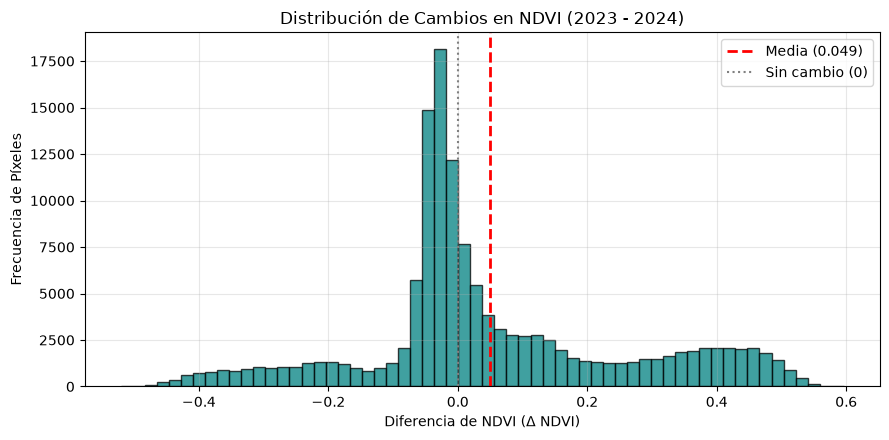

In [23]:
# Filtrar NaN para estadísticas limpias
diff_valid = ndvi_diff[~np.isnan(ndvi_diff)]

mean_val = np.mean(diff_valid)
std_val = np.std(diff_valid)
min_val = np.min(diff_valid)
max_val = np.max(diff_valid)

print("📊 --- ESTADÍSTICAS DEL CAMBIO (Δ NDVI) ---")
print(f"Mínimo:              {min_val:.4f}")
print(f"Máximo:              {max_val:.4f}")
print(f"Promedio (Media):    {mean_val:.4f}")
print(f"Desviación Estándar: {std_val:.4f}")

# Histograma
plt.figure(figsize=(9, 4.5))
plt.hist(diff_valid.flatten(), bins=60, color='teal', alpha=0.75, edgecolor='black')
plt.axvline(mean_val, color='red', linestyle='--', linewidth=2, label=f'Media ({mean_val:.3f})')
plt.axvline(0, color='gray', linestyle=':', linewidth=1.5, label='Sin cambio (0)')

plt.title('Distribución de Cambios en NDVI (2023 - 2024)', fontsize=12)
plt.xlabel('Diferencia de NDVI ($\Delta$ NDVI)')
plt.ylabel('Frecuencia de Píxeles')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()